# Неделя 4 — Bag-of-Words и TF-IDF

Цель: сравнить матрицы и значимые слова. Обучение словаря и IDF — строго на train; validation/test только transform.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'nlp_project').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from nlp_project.core import corpus, clean, tokens, metrics, SEED
df = corpus()
train, val, test = [df[df.split == s].copy() for s in ('train', 'validation', 'test')]


bow train: (589, 3138) validation: (196, 3138)


,term,weight
0,not,117
1,phone,99
2,great,52
3,good,47
4,product,33
5,headset,32
6,works,30
7,quality,30
8,battery,29
9,use,25


tfidf train: (589, 3138) validation: (196, 3138)


,term,weight
0,not,19.458815
1,phone,16.055966
2,great,13.199130
3,good,11.119877
4,works,10.162493
5,product,8.643705
6,headset,7.280331
7,quality,7.111127
8,battery,6.870600
9,price,6.265305


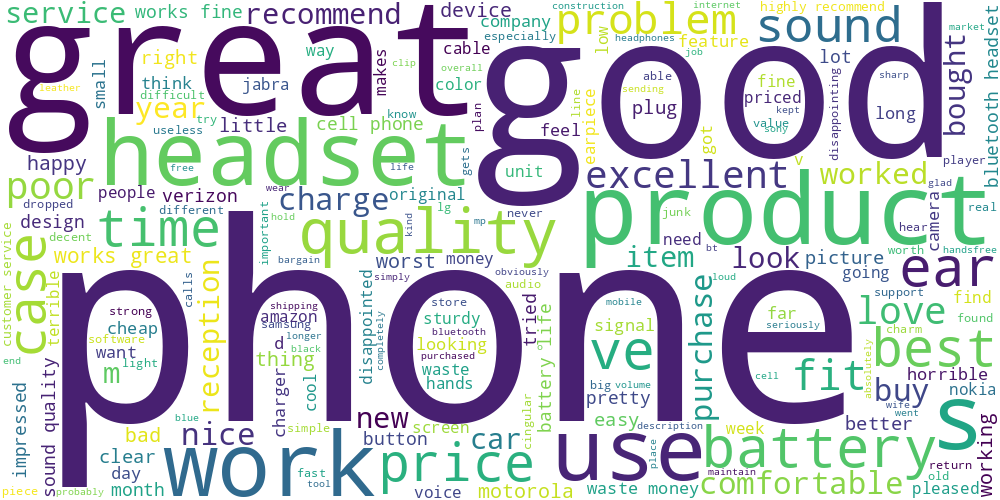

In [2]:
from nlp_project.classical import vectorizer
for method in ['bow', 'tfidf']:
    vec = vectorizer(method)
    x_train = vec.fit_transform(train.text)
    x_val = vec.transform(val.text)
    print(method, 'train:', x_train.shape, 'validation:', x_val.shape)
    weights = np.asarray(x_train.sum(axis=0)).ravel()
    top = np.argsort(weights)[-20:][::-1]
    display(pd.DataFrame({'term': vec.get_feature_names_out()[top], 'weight': weights[top]}))
display(Image(filename=str(ROOT / 'reports/figures/wordcloud.png')))


## Выводы

BOW отражает повторяемость, TF-IDF понижает вес общих слов. Суммы весов не показывают причинную важность для классификатора. Облако слов — описание train, не оценка качества.